# Hebrew real / synthetic audio: comparative EDA

This extends `dataset.ipynb` and `synthetic_eda.ipynb`. Read `COMPARATIVE_EDA_PLAN.md` for the prespecified units, exclusions and matching rules, and `DATASET_MATCHING_RECOMMENDATIONS_HE.md` for the Hebrew interpretation and proposed experiment.

**Decision:** the current synthetic pilot is a voice/configuration inventory and calibration set. It cannot support a credible text-disjoint real/fake benchmark: all 284 synthetic clips read one sentence, absent from the real aligned utterances. Source codec and clip-boundary preparation also differ by label. No paid calls, model training, source deletion, or audio generation occur here.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
import numpy as np
from IPython.display import display, Image, Markdown
ROOT=Path.cwd()
sys.path.insert(0,str(ROOT))
import comparative_analysis as analysis
OUT=ROOT/'comparison_outputs'
metrics=analysis.run()
display(pd.Series(metrics,name='value').to_frame())
def table(name): return pd.read_csv(OUT/(name+'.csv'))
def figure(name): display(Image(filename=str(OUT/'figures'/(name+'.png'))))


,value
exact_real_segment_text_matches,0
real_recordings,2398
real_speakers,85
real_hours,50.473816
real_reference_speakers,78
synthetic_configurations,284
synthetic_nominal_voices,116
synthetic_minutes,22.113517
synthetic_unique_texts,1
synthetic_human_verified,0


## 1. Eligibility and coverage of real aligned utterances

The funnel is sequential: a row removed earlier is not counted again later. Sum of aligned segment durations is neither original recorded hours nor guaranteed nonoverlapping speech time. Source session quality and segment alignment scores are dataset-provided heuristics, **not calibrated audio SNR or human intelligibility scores**. Thresholds are operational sensitivity choices, not validated universal cutoffs. Missing ages do not exclude audio. The full real corpus remains frozen.

In [2]:
display(table('real_eligibility_funnel'))
display(table('eligibility_sensitivity'))
coverage=table('proposed_speaker_coverage')
display(coverage.describe(include='all'))
display(coverage.loc[coverage.proposed_pairs.eq(0)])


,step,segments,removed_at_step,speakers,sessions,aligned_hours
0,all aligned rows,54122,0,85,2398,36.464262
1,source decoded and nonzero,53874,248,85,2376,36.456981
2,positive valid in-bounds timing,52672,1202,84,2360,36.434793
3,nonempty transcript,52657,15,84,2359,36.431982
4,session score >= 0.3,52042,615,83,2322,36.094184
5,segment alignment score >= 0.5,50103,1939,83,2318,35.338394


,session_threshold,alignment_threshold,prototype_lengths,segments,speakers,aligned_hours
0,0.3,0.5,False,50103,83,35.338394
1,0.3,0.5,True,27445,83,26.074544
2,0.8,0.8,False,38517,81,28.667969
3,0.8,0.8,True,23192,81,22.090630


,user_id,source_sessions,source_hours,eligible_prototype_segments,proposed_pairs
count,85,85.000000,85.000000,85.000000,85.000000
unique,85,NaN,NaN,NaN,NaN
top,0085e975-881a-4775-b437-c8fb97f7bf81,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN
mean,NaN,28.211765,0.592865,270.894118,3.623529
std,NaN,57.983802,0.824176,376.015736,1.034828
min,NaN,1.000000,0.003200,0.000000,0.000000
25%,NaN,3.000000,0.048433,17.000000,4.000000
50%,NaN,8.000000,0.157407,58.000000,4.000000
75%,NaN,29.000000,0.894550,450.000000,4.000000


,user_id,source_sessions,source_hours,eligible_prototype_segments,proposed_pairs
32,72063563-00ed-4c5a-84f7-1b55b009071a,1,0.019817,0,0
65,c88f6064-5a8c-4f31-954e-414c843c9c2b,12,0.317867,0,0
69,d1d5a9d7-0133-4fff-83ce-0db936d6367c,1,0.003200,0,0
70,d5af59c6-3e96-45e3-bf7a-7b311b5213f1,3,0.080217,0,0


## 2. Voice exposure and demographic information

Model/voice configurations are repeated measurements, not independent speakers. Provider:voice IDs are conservative nominal identity groups, not biometric identity guarantees. Stock voice gender/age descriptors, real source biological-sex/birth-year fields and auditory impressions represent different concepts and must remain separate.

The automated age reviewer returned one adult category for every synthetic sample; this is rejected as uninformative. Thirty-five nominal voice groups also have conflicting presentation estimates across model versions. Neither result supports assigning synthetic biological ages/sexes. Human listening is still pending for all synthetic samples; the 14 previous real excerpt judgments remain excerpt-scoped and are not propagated.

In [3]:
display(table('synthetic_family_exposure'))
display(table('label_distributions'))
display(table('synthetic_review_queue'))
display(table('reference_metadata_coverage'))


,family,configurations,nominal_voices,seconds,configuration_share,audio_time_share
0,elevenlabs,84,21,348.960,0.295775,0.263007
1,google,90,30,458.680,0.316901,0.345701
2,minimax,90,45,434.691,0.316901,0.327621
3,speechify,20,20,84.480,0.070423,0.063671


,unit,field,value,count
0,real_speakers,source_sex,male,46
1,real_speakers,source_sex,female,25
2,real_speakers,source_sex,unknown,14
3,real_speakers,age_proxy_bins,unknown,24
4,real_speakers,age_proxy_bins,30-39,24
5,real_speakers,age_proxy_bins,40-49,13
6,real_speakers,age_proxy_bins,50-59,10
7,real_speakers,age_proxy_bins,18-29,7
8,real_speakers,age_proxy_bins,60-69,6
9,real_speakers,age_proxy_bins,0-17,1


,sample_id,model,voice,duration_s,rms_dbfs,quiet_fraction_45dbfs,review_reasons
0,c639f1a88df9d7edd156,google/gemini-3.8-flash-lite-tts,Umbriel,8.2400,-17.561750,0.322816,outlier_duration_s
1,e7a8fbedc6a062df60d6,google/gemini-3.8-flash-lite-tts,Schedar,6.5600,-17.091522,0.246951,outlier_duration_s
2,3fb7fc1fdd4207fc7e59,minimax/speech-2.8-hd,English_Whispering_girl,6.2475,-44.660041,0.615385,quiet_majority;low_rms;outlier_rms_dbfs;outlie...
3,e9ace176259d73f82dbc,minimax/speech-2.8-hd,English_FriendlyPerson,5.3475,-36.211048,0.460674,outlier_rms_dbfs;outlier_quiet_fraction_45dbfs
4,dce053f31ec083a5643f,minimax/speech-2.8-hd,English_PatientMan,6.6435,-30.056455,0.231928,outlier_duration_s
5,e8bdc522071574d928ea,minimax/speech-2.8-turbo,English_Whispering_girl,5.4555,-44.707436,0.555147,quiet_majority;low_rms;outlier_rms_dbfs;outlie...
6,4fa56420eb32f99f3eed,minimax/speech-2.8-turbo,English_FriendlyPerson,4.2675,-36.426566,0.417840,outlier_rms_dbfs;outlier_quiet_fraction_45dbfs


,sex_label,age_proxy_bin,reference_excerpts
0,female,0-17,1
1,female,18-29,4
2,female,30-39,6
3,female,40-49,4
4,female,50-59,5
5,female,60-69,1
6,female,unknown,4
7,male,18-29,2
8,male,30-39,16
9,male,40-49,8


## 3. Text and codec confounds

Zero exact normalized real-segment matches were found for the one synthetic sentence. Native real codecs are Opus/AAC; synthetic native outputs are MP3/PCM. Conversion to the same WAV format does not undo lossy codec history. Original source metadata must not be given to a detector.

The acoustic comparison below uses all 284 synthetic WAVs and an existing, deliberately selected reference of 78 real speakers, one short excerpt each. This is a descriptive reference, **not a random representative sample** of the 50-hour real corpus. Real boundaries follow alignment, synthetic boundaries retain full generated output; edge differences are therefore inseparable from extraction method here. Transcript content and phonetic composition remain uncontrolled.

In [4]:
display(table('native_codec_confound'))
assert metrics['exact_real_segment_text_matches']==0
assert metrics['synthetic_unique_texts']==1
common=table('common_audio_features')
display(common.groupby('label')[['duration_s','rms_dbfs','quiet_fraction_45dbfs','edge_quiet_fraction']].agg(['count','median','min','max']))


,label,native_codec,samples
0,real,aac,124
1,real,opus,2274
2,synthetic,mp3float,194
3,synthetic,pcm_s16le,90


duration_s                      rms_dbfs                        \
               count   median   min   max    count     median        min   
label                                                                      
real              78  3.67000  3.02  6.96       78 -22.247754 -32.616429   
synthetic        284  4.51975  3.36  8.24      284 -19.531457 -44.707730   

                     quiet_fraction_45dbfs                                \
                 max                 count    median       min       max   
label                                                                      
real      -13.001842                    78  0.116335  0.006369  0.423729   
synthetic -13.611366                   284  0.164103  0.041667  0.615385   

          edge_quiet_fraction                           
                        count    median  min       max  
label                                                   
real                       78  0.000000  0.0  0.046154  
synthetic                 284  0.088912  0.0  0.206349

## 4. Common acoustic measurements and group-weighted effects

Identical code reads saved mono 16 kHz PCM16 WAVs. Spectral summaries use 20 ms Hann-window frames above -45 dBFS. Quiet masks are absolute-energy proxies, not speech activity labels or noise estimates. The energy percentile range is **not SNR**, and digital zeros can inflate it.

Each synthetic provider:voice group contributes its median over versions, preventing four versions of one voice from being counted as four independent people. Effect signs are synthetic minus real. Cliff's delta and Wasserstein distances are descriptive. Bootstrap intervals resample observed real speaker/nominal voice groups (1,000 repetitions, fixed seed); correlated voices within providers and selected real references limit interpretation. No hypothesis tests or population claims are made.

`in_sample_orientation_free_auc` measures one-variable separability on the same observed group medians. It is a shortcut warning, **not detector performance, validation AUC, EER, or generalization**.

,view,feature,real_groups,synthetic_groups,real_median,synthetic_median,median_difference,mean_difference,smd,cliffs_delta,wasserstein_distance,bootstrap_mean_difference_low,bootstrap_mean_difference_high,in_sample_orientation_free_auc
0,original,duration_s,78,116,3.6700,4.4948,0.8247,0.7448,1.1192,0.6480,0.7767,0.5377,0.9416,0.8240
1,original,rms_dbfs,78,116,-22.2478,-19.7252,2.5226,0.9259,0.2164,0.1992,1.5786,-0.3383,2.0352,0.5996
2,original,quiet_fraction_45dbfs,78,116,0.1163,0.1767,0.0604,0.0418,0.5704,0.3840,0.0511,0.0201,0.0622,0.6920
3,original,edge_quiet_fraction,78,116,0.0000,0.0946,0.0946,0.0941,4.1197,0.9987,0.0941,0.0887,0.0996,0.9993
4,original,energy_dynamic_range_db,78,116,28.7074,44.6067,15.8993,8.2193,0.4030,0.4788,12.9267,1.6474,13.6317,0.7394
5,original,spectral_centroid_hz,78,116,467.0351,430.8520,-36.1830,-50.5068,-0.3650,-0.1813,51.2702,-94.4377,-11.0461,0.5906
6,original,highband_energy_fraction,78,116,0.0009,0.0013,0.0004,0.0006,0.2416,0.3053,0.0008,-0.0000,0.0014,0.6526
7,original,spectral_flatness,78,116,0.0013,0.0039,0.0026,0.0024,0.7821,0.6132,0.0024,0.0015,0.0032,0.8066
8,original,zero_crossing_fraction,78,116,0.1372,0.1248,-0.0124,-0.0163,-0.4901,-0.2244,0.0213,-0.0271,-0.0068,0.6122


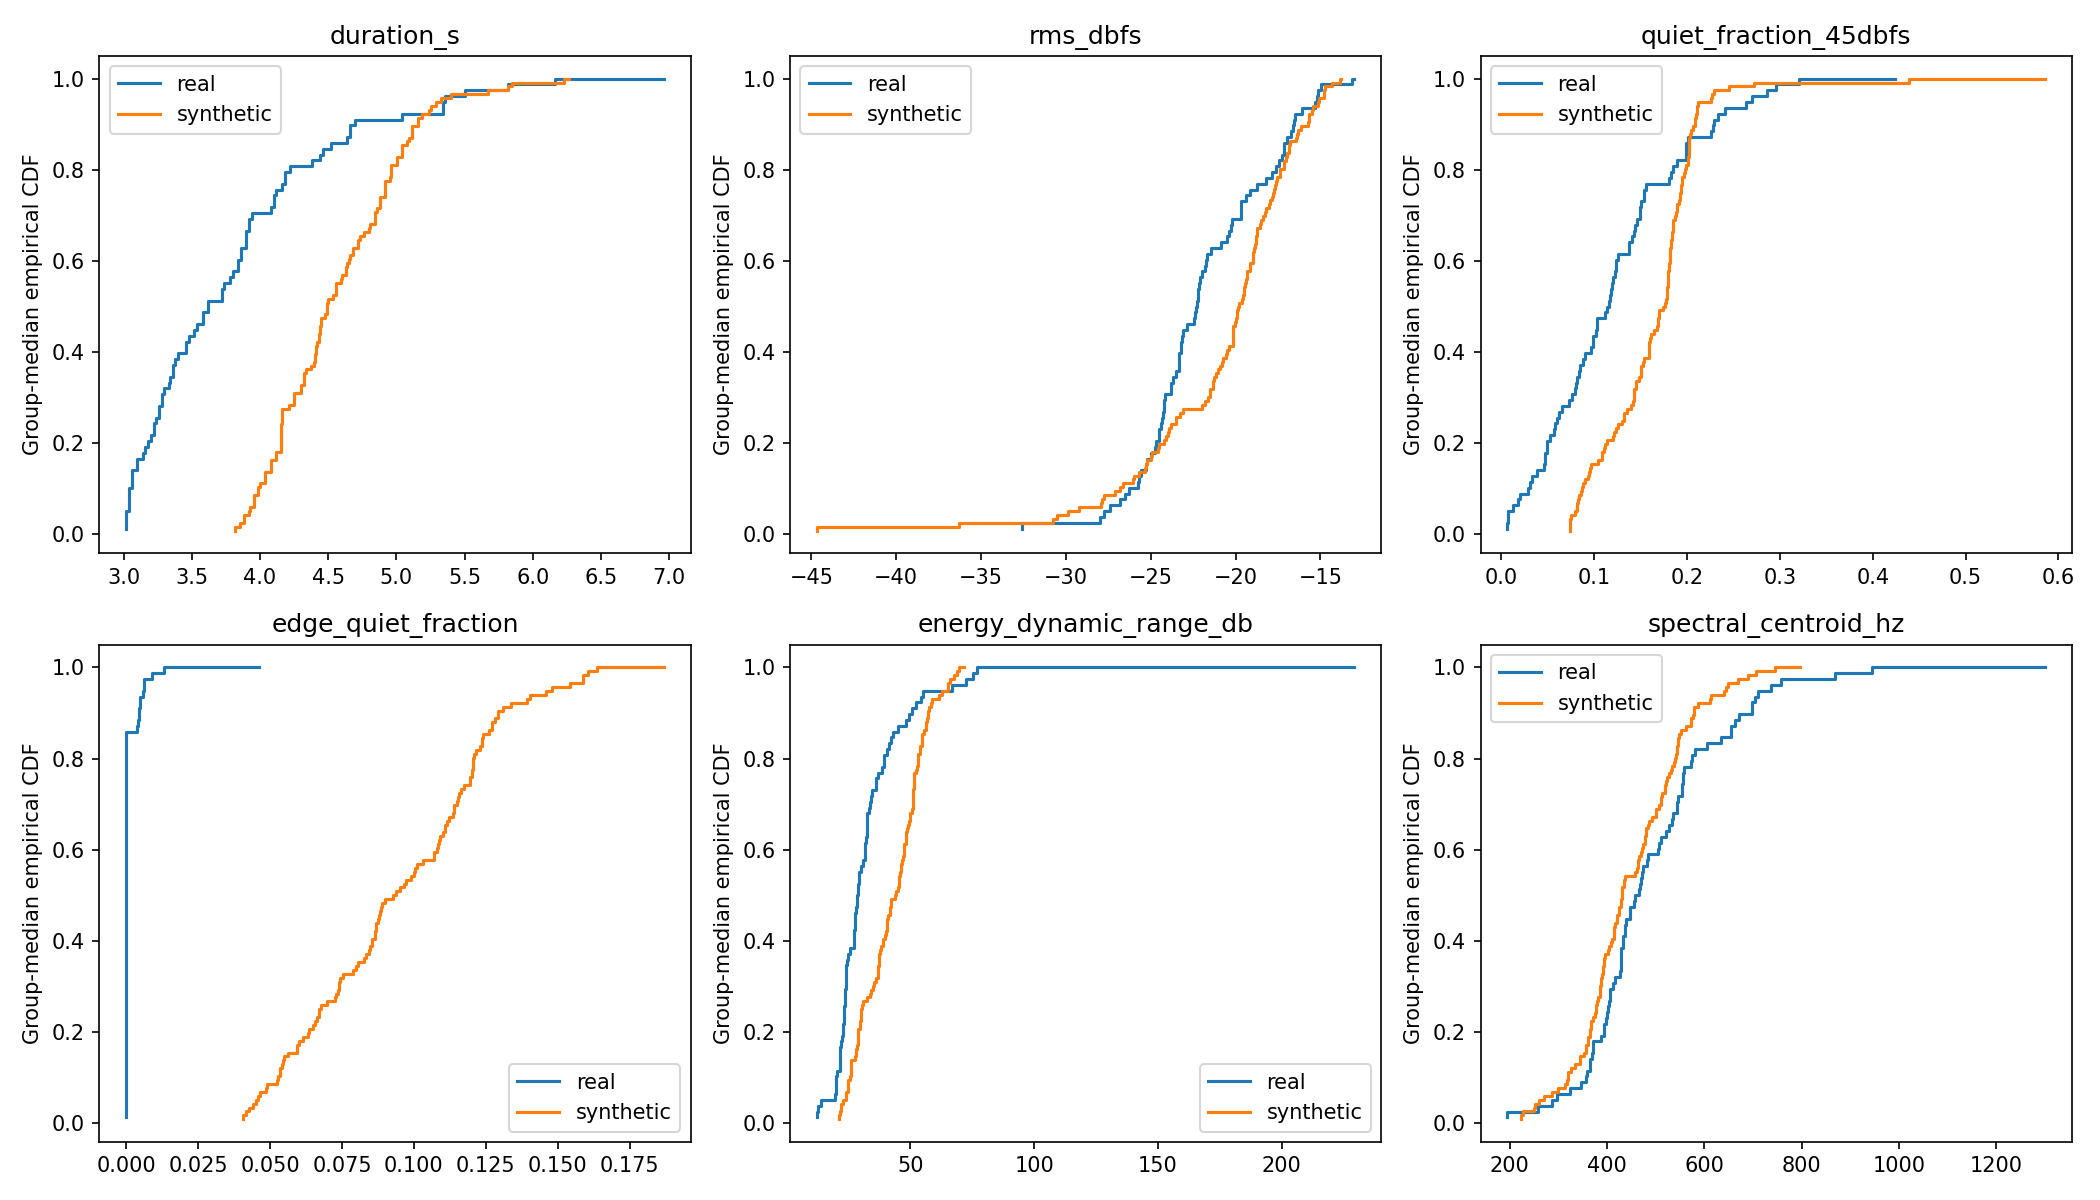

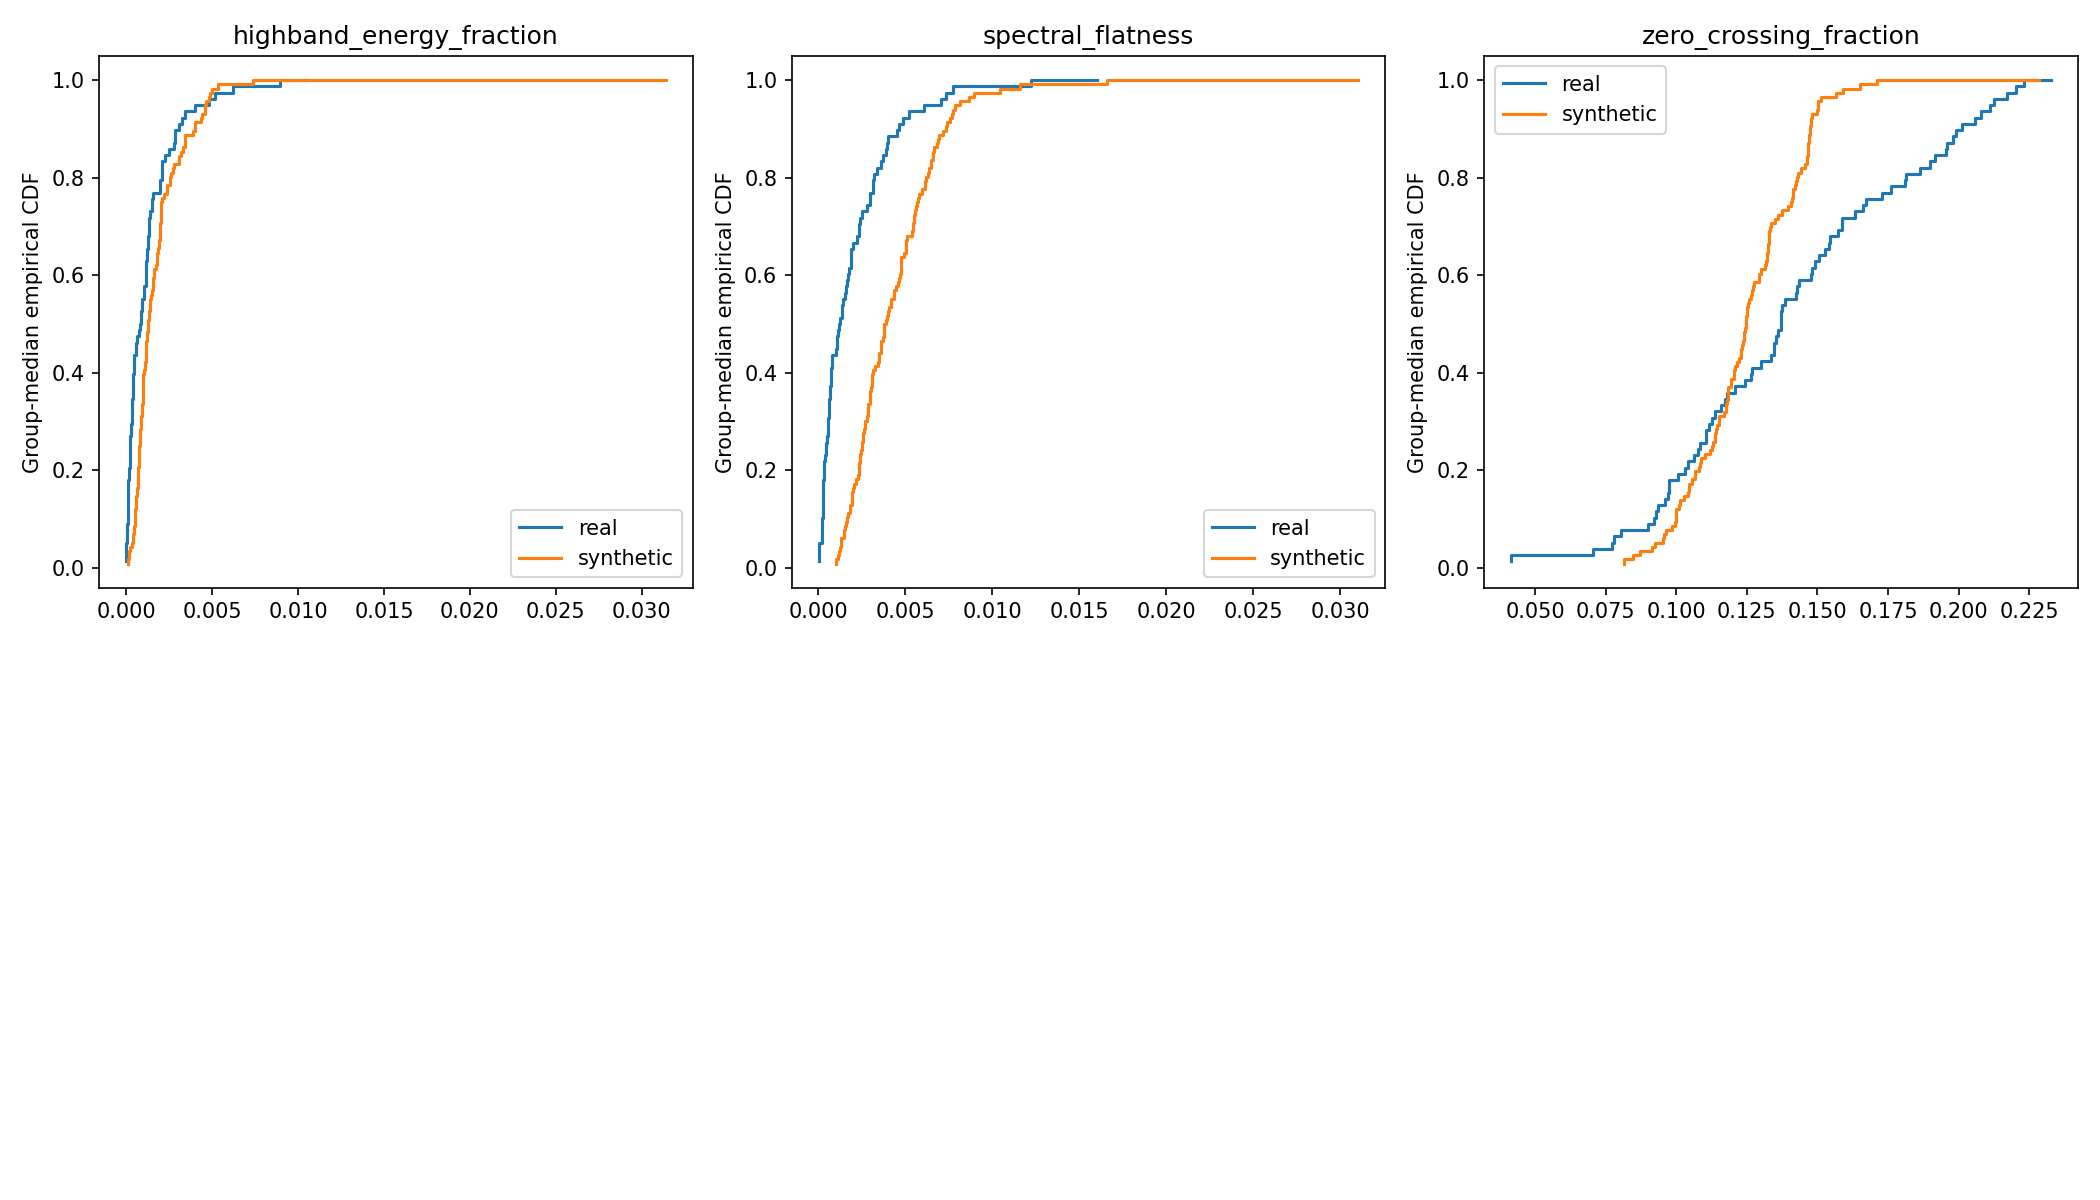

In [5]:
effects=table('group_effect_sizes')
display(effects.loc[effects.view.eq('original')].round(4))
figure('acoustic_distributions')
figure('spectral_distributions')


## 5. Sensitivity to preparation choices

Two separate in-memory views: remove at most 0.25 s of estimated quiet frames per edge; or scale RMS toward -23 dBFS with peak capped at 0.99. No transformed audio is saved over originals. These are sensitivity analyses, **not a finalized preprocessing policy**. Normalization alone leaves the edge shortcut; capped trimming reduces it but does not establish a fair benchmark. Frame threshold effects and crop phase can change spectral summaries.

view,duration_word_matched,edge_trimmed,level_normalized,original
feature,,,,
duration_s,0.297,0.580,1.119,1.119
edge_quiet_fraction,2.598,0.918,3.686,4.120
energy_dynamic_range_db,0.235,-0.403,0.418,0.403
highband_energy_fraction,-0.075,0.243,0.249,0.242
quiet_fraction_45dbfs,0.133,-0.418,0.578,0.570
rms_dbfs,0.718,0.301,0.160,0.216
spectral_centroid_hz,-0.468,-0.371,-0.373,-0.365
spectral_flatness,0.296,0.796,0.775,0.782
zero_crossing_fraction,-0.636,-0.409,-0.490,-0.490


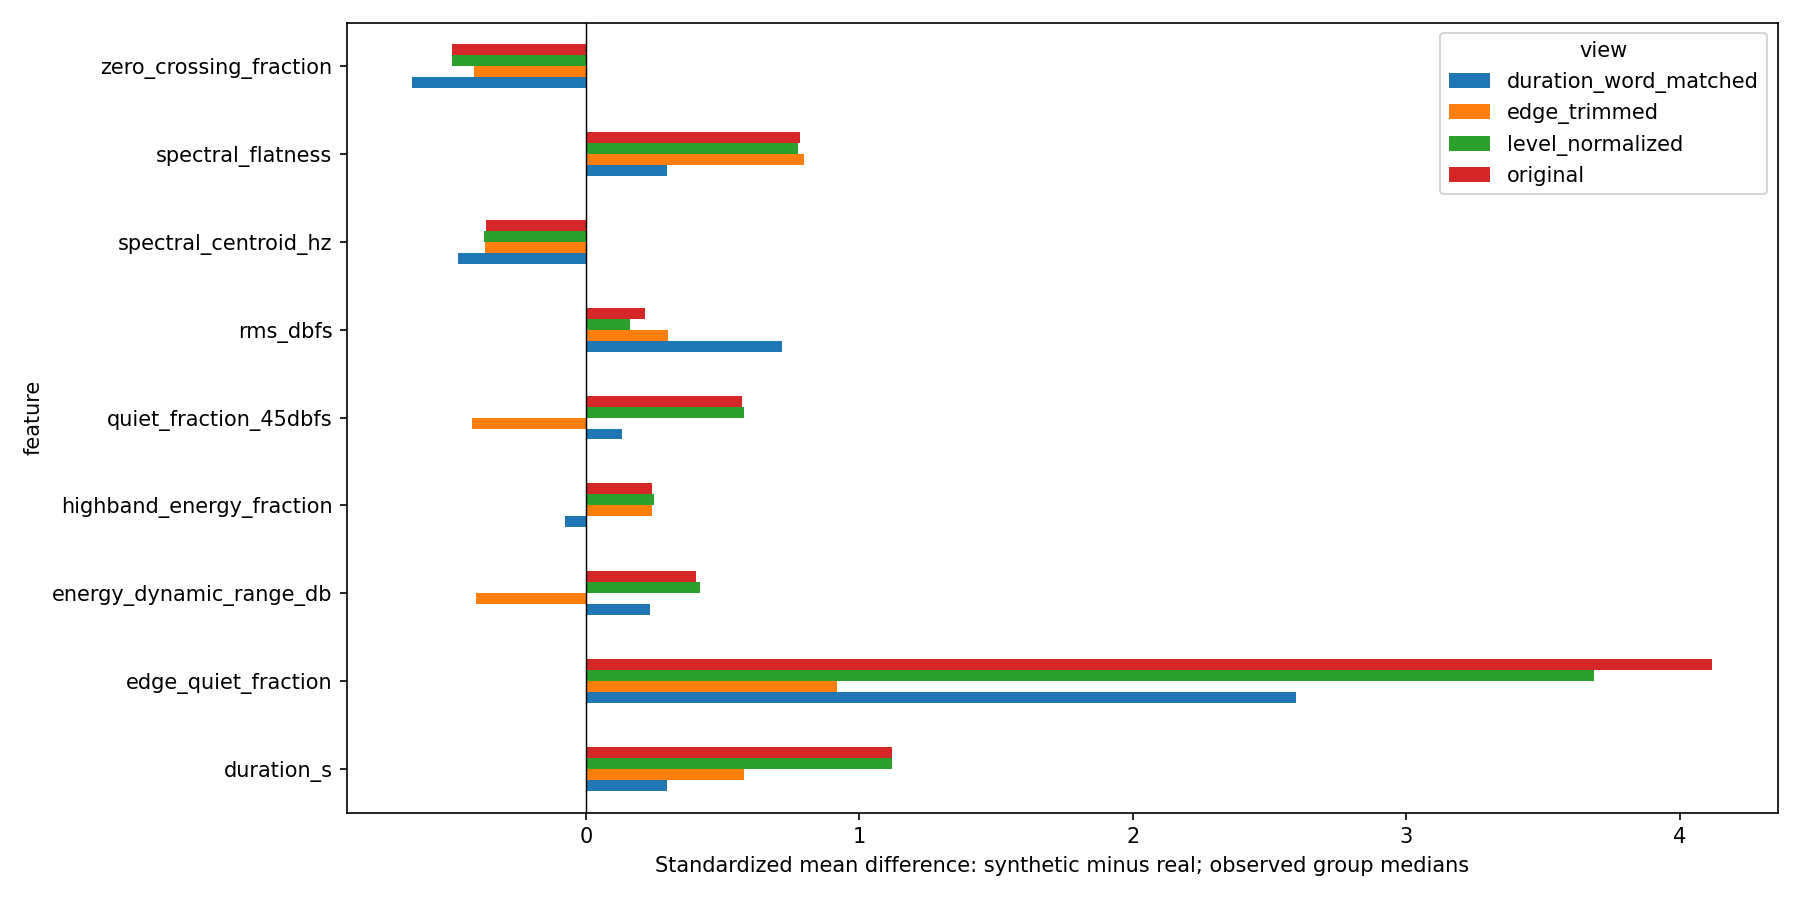

In [6]:
display(effects.pivot(index='feature',columns='view',values='smd').round(3))
figure('effect_sensitivities')


## 6. Duration / word-count matching diagnostic

Eligibility: exactly eight real aligned words; duration difference <=0.5 s; each real speaker and nominal synthetic voice used at most once. Four synthetic families receive equal counts. Mixed-integer optimization maximizes feasible equal-family cardinality, then minimizes total absolute duration difference. It certifies **44 pairs, 11 per family** under this selected reference and caliper; this is not the maximum matching capacity of the whole real corpus.

Texts still differ. This diagnostic cannot be used as same-text training/evaluation data. Duration effects shrink, but edge/level differences persist and some effects grow. Matching covariates does not prove removal of confounds. Bootstrap intervals in this table are the same separate-group composition diagnostic, not paired treatment-effect inference.

,pairs,mean_duration_gap,max_duration_gap
family,,,
elevenlabs,11,0.347273,0.5000
google,11,0.032727,0.1000
minimax,11,0.204773,0.4635
speechify,11,0.229818,0.4160


,view,feature,real_groups,synthetic_groups,real_median,synthetic_median,median_difference,mean_difference,smd,cliffs_delta,wasserstein_distance,bootstrap_mean_difference_low,bootstrap_mean_difference_high,in_sample_orientation_free_auc
27,duration_word_matched,duration_s,44,44,3.8800,4.1520,0.2720,0.1976,0.2975,0.2774,0.2036,-0.0793,0.4634,0.6387
28,duration_word_matched,rms_dbfs,44,44,-22.3086,-18.7083,3.6003,2.5697,0.7182,0.4091,2.5697,1.1936,4.0891,0.7045
29,duration_word_matched,quiet_fraction_45dbfs,44,44,0.1209,0.1493,0.0285,0.0091,0.1332,0.1813,0.0316,-0.0191,0.0362,0.5907
30,duration_word_matched,edge_quiet_fraction,44,44,0.0000,0.1012,0.1012,0.0905,2.5980,0.9649,0.0905,0.0766,0.1052,0.9824
31,duration_word_matched,energy_dynamic_range_db,44,44,28.9563,42.7694,13.8131,5.7061,0.2349,0.3729,13.2195,-5.4760,13.9516,0.6865
32,duration_word_matched,spectral_centroid_hz,44,44,513.1145,416.2379,-96.8766,-74.2003,-0.4679,-0.2789,76.4069,-141.6193,-16.1001,0.6395
33,duration_word_matched,highband_energy_fraction,44,44,0.0010,0.0008,-0.0002,-0.0002,-0.0753,-0.0083,0.0004,-0.0011,0.0007,0.5041
34,duration_word_matched,spectral_flatness,44,44,0.0016,0.0026,0.0009,0.0008,0.2960,0.3740,0.0013,-0.0004,0.0019,0.6870
35,duration_word_matched,zero_crossing_fraction,44,44,0.1427,0.1234,-0.0193,-0.0222,-0.6358,-0.3213,0.0261,-0.0360,-0.0078,0.6606


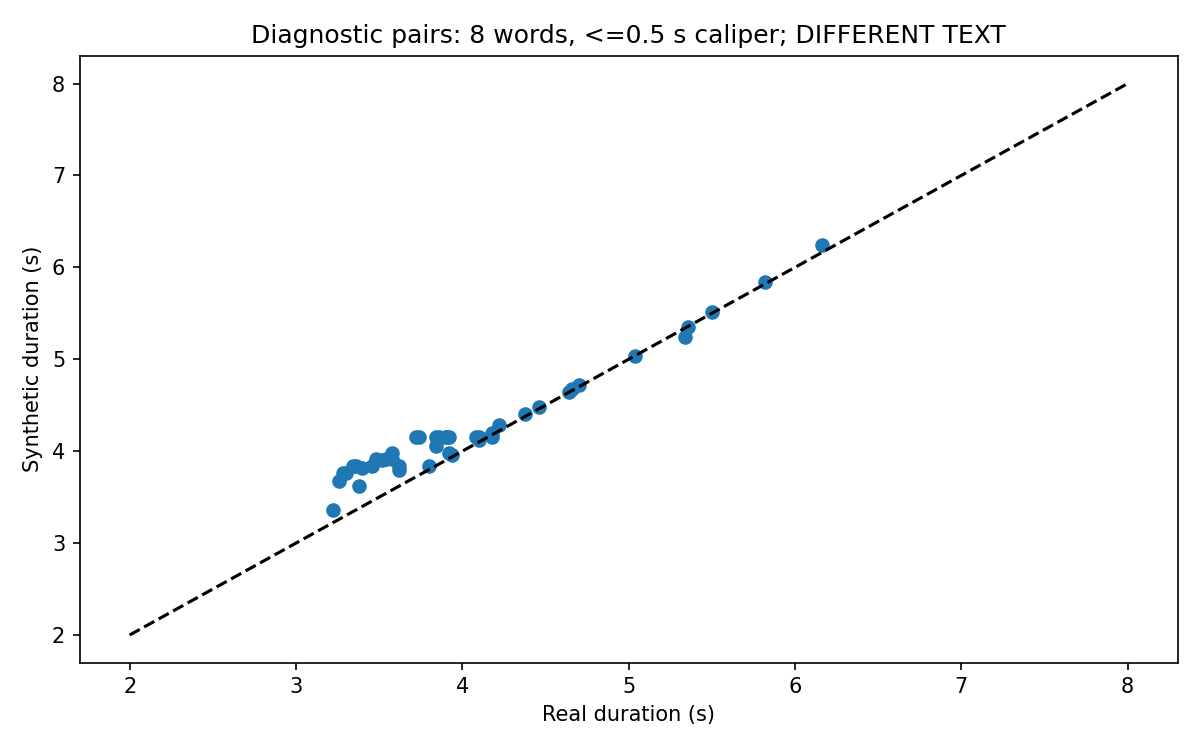

In [7]:
pairs=table('diagnostic_duration_word_pairs')
display(pairs.groupby('family').agg(pairs=('real_sample_id','size'),mean_duration_gap=('duration_difference_s','mean'),max_duration_gap=('duration_difference_s','max')))
display(effects.loc[effects.view.eq('duration_word_matched')].round(4))
figure('diagnostic_pairs')
assert pairs.real_group_id.is_unique and pairs.synthetic_group_id.is_unique
assert pairs.duration_difference_s.le(.5+1e-9).all()
assert pairs.groupby('family').size().nunique()==1


## 7. Proposed true same-text experiment — not generated

Select up to four globally normalized-text-unique real utterances per eligible speaker, round-robin. Require positive in-bounds timing, session and alignment scores >=0.8, 2–10 s, 6–14 words, and >=80% Hebrew letters among letters. This yields **308 proposed real utterances from 81 speakers**, assigned provisionally 77 per synthetic family. Around 17.10 minutes of real excerpts; synthetic duration must be measured after generation and is not assumed equal.

Proposed source cuts still need listening, boundary and transcript validation. These thresholds retain 81/85 source IDs; four remain in the coverage audit, not deleted. Model/voice and split columns intentionally remain unassigned. Each target should later have one authentic excerpt and a synthetic rendering of that exact Hebrew text. Balance family and voice exposure within frozen partitions; reserve an independent evaluation pool first. Different versions sharing a voice must stay in the same identity partition.

The one-sentence pilot belongs in calibration only. It must not be randomly spread across train/dev/test. For text-disjoint evaluation of the full real corpus, repeated document passages can connect many speakers: retain one partition's copies and explicitly discard conflicting copies, or build a curated text-unique subset and audit normalized text, near-duplicates, recording and speaker groups after splitting. Never promise full simultaneous speaker/text disjointness while silently retaining leakage.

In [8]:
display(table('proposed_family_allocation'))
proposal=table('proposed_same_text_pairs')
display(proposal[['proposed_pair_id','user_id','duration_s','word_count','desired_family','text']].head(12))
assert proposal.exact_text_group.is_unique
assert proposal.groupby('user_id').size().le(4).all()
assert proposal.quality_score.ge(.8).all() and proposal.segment_alignment_score.ge(.8).all()
assert proposal.duration_s.between(2,10).all() and proposal.word_count.between(6,14).all()
assert proposal.hebrew_letter_fraction.ge(.8).all()
assert proposal['split'].isna().all() and proposal.assigned_model.isna().all()


,desired_family,proposed_pairs,real_seconds
0,elevenlabs,77,263.49
1,google,77,253.98
2,minimax,77,248.63
3,speechify,77,259.82


,proposed_pair_id,user_id,duration_s,word_count,desired_family,text
0,proposed_0001,0085e975-881a-4775-b437-c8fb97f7bf81,4.67,10,elevenlabs,שנדרשה לשלם לאחר מלחמת העולם הראשונה העיקו מא...
1,proposed_0002,021c1fbf-05c6-4a5c-9f8c-89b510a86a83,2.60,8,google,מכבי חיפה סיימה את העונה במקום האחרון בעונה
2,proposed_0003,04d374d1-9317-4cf1-9961-158385f3f9f0,3.16,7,minimax,"התקדמות משמעותית בתחום הצלילה נעשתה במאה ה-19,"
3,proposed_0004,10fb2bc7-dcf8-48e2-86d6-088a56abfb54,3.58,10,speechify,שם רבות מציפורים אלו נלכדות באופן בלתי חוקי ב...
4,proposed_0005,1184cab7-edc8-4139-ac5b-e2ce5fb72963,2.32,6,elevenlabs,"המשפט העליון של מדינת ישראל לפיה,"
5,proposed_0006,148c62d5-face-4b18-b666-bda8f18d66b6,4.32,10,google,לאחר 3 חודשי שירות הוא נעצר על ידי המשטרה המק...
6,proposed_0007,176b81e9-f974-453d-b337-c0a8a9bc1759,3.36,10,minimax,שהם מוכתבים על ידי החברה עבודה במשרה מתשע עד ...
7,proposed_0008,20c0ff8b-be92-4110-8793-6de3904e4c14,2.70,7,speechify,והגיעה ליפן יחד עם הנייר במאה השישית.
8,proposed_0009,224a4c01-03cf-4b12-9d8c-15c72591143e,2.50,7,elevenlabs,המתרחשת כמה עשרות שנים לפני תחילת העלילה
9,proposed_0010,27129c7f-1195-4f7c-9406-ccadec96223d,2.74,7,google,יחד עם רבים מתלמידי ישיבת מיר לווילנה


## 8. Reproducibility and next decision

Read the detailed Hebrew report for handling policy, matching quotas, demographic limitations, split protocols and priority order. No additional synthesis or budget expenditure was performed here.

Primary guidance: [ASVspoof 2021 evaluation plan](https://www.asvspoof.org/asvspoof2021/asvspoof2021_evaluation_plan.pdf) motivates auditing coding/transmission conditions; [Smeu et al., CVPR 2025](https://openaccess.thecvf.com/content/CVPR2025/papers/Smeu_Circumventing_Shortcuts_in_Audio-visual_Deepfake_Detection_Datasets_with_Unsupervised_Learning_CVPR_2025_paper.pdf) documents leading-silence shortcuts; [ivrit-ai dataset card](https://huggingface.co/datasets/ivrit-ai/crowd-recital) supplies schema context. These publications motivate checks; their benchmark results are not evidence about this pilot.

Run: `python build_comparative_notebook.py`, `python execute_comparative_eda.py`, `python verify_comparative_eda.py`. The notebook regenerates offline tables/plots. Source audio hashes are checked against the frozen preceding EDA manifests.

In [9]:
display(json.loads((OUT/'provenance.json').read_text()))
assert len(common)==362
assert common.sample_id.is_unique
assert common.groupby('label').group_id.nunique().to_dict()=={'real':78,'synthetic':116}
print('Completed offline comparison: no API requests, no source audio mutations, no new human labels.')


{'seed': 20261116,
 'python': '3.12.3 | packaged by conda-forge | (main, Apr 15 2024, 18:20:11) [MSC v.1938 64 bit (AMD64)]',
 'platform': 'Windows-11-10.0.26200-SP0',
 'input_hashes': {'eda_outputs\\recording_features.csv': '307d35bfae771956403c21ad83413ff246e6d65b1fc9248cc9dfb57621eb8b15',
  'eda_outputs\\segments.csv': '9efdab84d360093a32eaf91d1856699edf553e0316d3dbffbcf6ceb6762ba44c',
  'eda_outputs\\segment_quality.csv': '3cf7b658aad21143774353706ac028ca6a2d29b24ce624b38d0e3066a51d9f93',
  'synthetic_pilot\\analysis\\sample_features.csv': '20ab4f7a9753af4d5477c4c1f4d94e3c1ea9a7efa8176955bf182d6c3074ac04',
  'synthetic_pilot\\human_reference.csv': '051914777cb1161f9396df04b0abd3bfea024e10723a8880f8779bee2c904b8d',
  'comparative_analysis.py': '89e9e57cfd49d9c33855a9927ae420df7100167262ab36631d256f5f580f7ce8',
  'comparative_audio.py': '4fa0fde5e18616ee45a5b3806f4885d398f894d55e7c28d1f2f1c6c305493c6c',
  'COMPARATIVE_EDA_PLAN.md': '7751e5b6244d383a586b3d881afee9fcb9a54db1033b7f59a04

Completed offline comparison: no API requests, no source audio mutations, no new human labels.
